# Week 2: Advanced Data Visualization and Storytelling with Python
Run each cell in order. Six visualizations are saved to `figures/`.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
sns.set_theme(style="whitegrid")
OUT = Path("figures")
OUT.mkdir(exist_ok=True)
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)
print("Dataset shape:", df.shape)
display(df.head())
display(df.isna().sum().to_frame("missing_count"))

Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,missing_count
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [ ]:
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df["Sex"] = df["Sex"].astype(str).str.strip().str.lower()
df["Embarked"] = df["Embarked"].astype(str).str.strip().str.upper()
df["FamilySize"] = df["SibSp"].fillna(0) + df["Parch"].fillna(0) + 1
df["SurvivalLabel"] = df["Survived"].map({0: "Did not survive", 1: "Survived"})
print("Prepared shape:", df.shape)

Prepared shape: (891, 14)


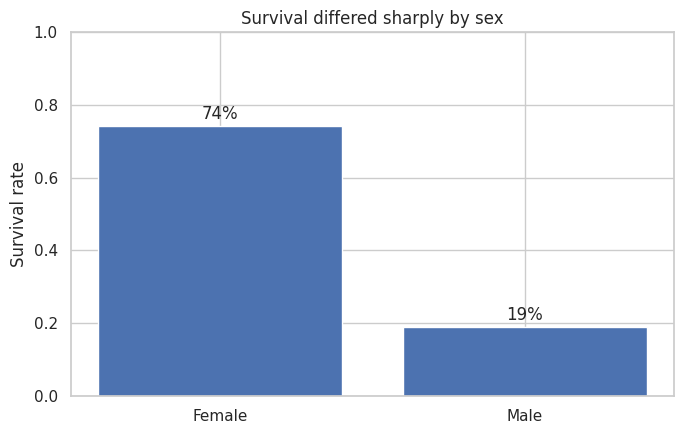

In [ ]:
# Chart 1: Survival by sex
rates = df.groupby("Sex")["Survived"].mean().reindex(["female", "male"])
fig, ax = plt.subplots(figsize=(7,4.5))
bars = ax.bar(["Female","Male"], rates.values)
ax.set_ylim(0,1); ax.set_ylabel("Survival rate"); ax.set_title("Survival differed sharply by sex")
for b,v in zip(bars,rates.values): ax.text(b.get_x()+b.get_width()/2,v+.02,f"{v:.0%}",ha="center")
plt.tight_layout(); fig.savefig(OUT/"01_survival_by_sex.png",dpi=180); plt.show()

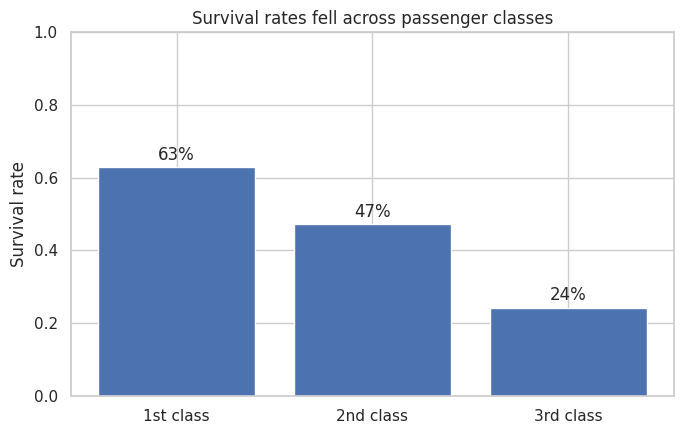

In [ ]:
# Chart 2: Survival by passenger class
rates = df.groupby("Pclass")["Survived"].mean()
vals = [rates[1], rates[2], rates[3]]
fig, ax = plt.subplots(figsize=(7,4.5))
bars = ax.bar(["1st class","2nd class","3rd class"],vals)
ax.set_ylim(0,1); ax.set_ylabel("Survival rate"); ax.set_title("Survival rates fell across passenger classes")
for b,v in zip(bars,vals): ax.text(b.get_x()+b.get_width()/2,v+.02,f"{v:.0%}",ha="center")
plt.tight_layout(); fig.savefig(OUT/"02_survival_by_class.png",dpi=180); plt.show()

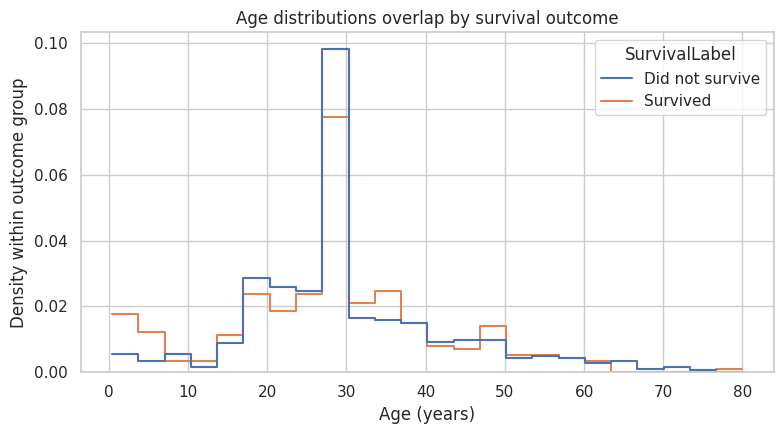

In [ ]:
# Chart 3: Age distributions by survival outcome
fig, ax = plt.subplots(figsize=(8,4.5))
sns.histplot(data=df,x="Age",hue="SurvivalLabel",bins=24,stat="density",common_norm=False,element="step",fill=False,ax=ax)
ax.set_title("Age distributions overlap by survival outcome")
ax.set_xlabel("Age (years)"); ax.set_ylabel("Density within outcome group")
plt.tight_layout(); fig.savefig(OUT/"03_age_distribution_by_outcome.png",dpi=180); plt.show()

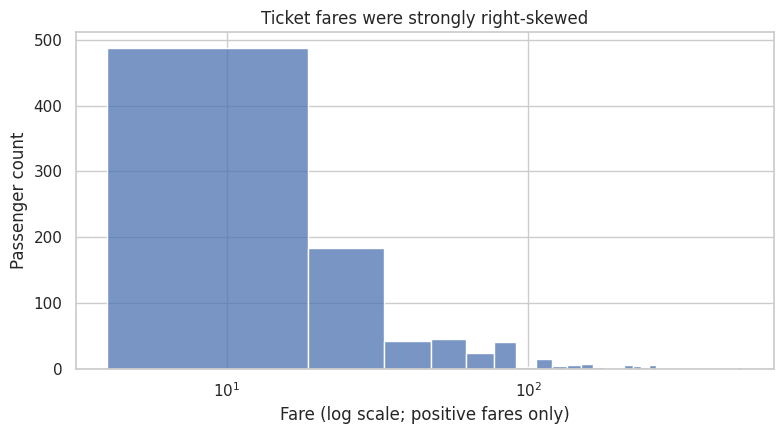

In [ ]:
# Chart 4: Positive fares on a log-scaled axis
fig, ax = plt.subplots(figsize=(8,4.5))
sns.histplot(df.loc[df["Fare"]>0,"Fare"],bins=35,ax=ax)
ax.set_xscale("log"); ax.set_title("Ticket fares were strongly right-skewed")
ax.set_xlabel("Fare (log scale; positive fares only)"); ax.set_ylabel("Passenger count")
plt.tight_layout(); fig.savefig(OUT/"04_fare_distribution_log.png",dpi=180); plt.show()

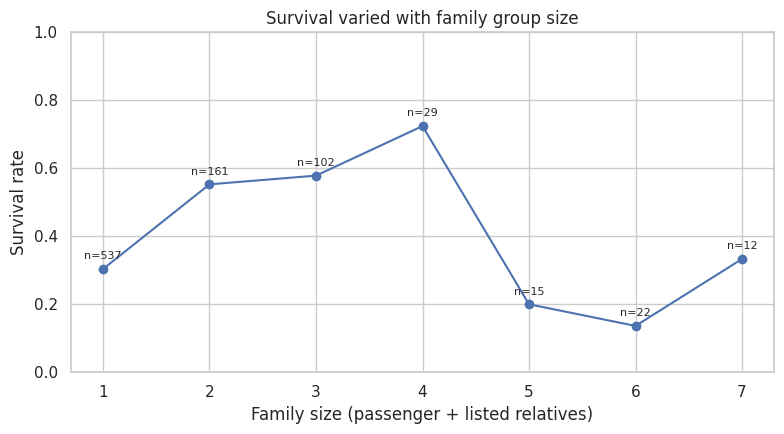

In [ ]:
# Chart 5: Family size vs survival; annotate group sizes and show n >= 8
fam = df.groupby("FamilySize")["Survived"].agg(["mean","count"]).reset_index()
fam = fam[fam["count"]>=8]
fig, ax = plt.subplots(figsize=(8,4.5))
ax.plot(fam["FamilySize"],fam["mean"],marker="o")
ax.set_ylim(0,1); ax.set_xlabel("Family size (passenger + listed relatives)")
ax.set_ylabel("Survival rate"); ax.set_title("Survival varied with family group size")
for _,r in fam.iterrows():
    ax.annotate(f"n={int(r['count'])}",(r["FamilySize"],r["mean"]),textcoords="offset points",xytext=(0,7),ha="center",fontsize=8)
plt.tight_layout(); fig.savefig(OUT/"05_family_size_survival.png",dpi=180); plt.show()

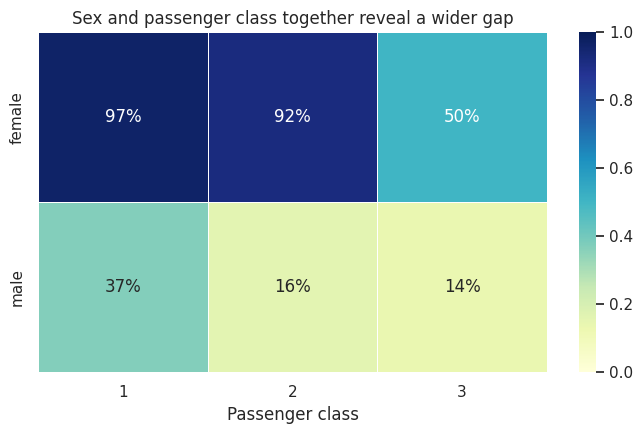

In [ ]:
# Chart 6: Heatmap by sex and passenger class
pivot = df.pivot_table(index="Sex",columns="Pclass",values="Survived",aggfunc="mean").reindex(["female","male"])
fig, ax = plt.subplots(figsize=(7,4.5))
sns.heatmap(pivot,annot=True,fmt=".0%",cmap="YlGnBu",vmin=0,vmax=1,linewidths=.6,ax=ax)
ax.set_title("Sex and passenger class together reveal a wider gap")
ax.set_xlabel("Passenger class"); ax.set_ylabel("")
plt.tight_layout(); fig.savefig(OUT/"06_survival_sex_class_heatmap.png",dpi=180); plt.show()

In [ ]:
# Tables to use when writing the report
display(df.groupby("Sex")["Survived"].agg(["mean","count"]))
display(df.groupby("Pclass")["Survived"].agg(["mean","count"]))
display(df.groupby("FamilySize")["Survived"].agg(["mean","count"]))
print("Saved figure files:", sorted(p.name for p in OUT.glob("*.png")))

,mean,count
Sex,,
female,0.742038,314
male,0.188908,577


,mean,count
Pclass,,
1,0.629630,216
2,0.472826,184
3,0.242363,491


,mean,count
FamilySize,,
1,0.303538,537
2,0.552795,161
3,0.578431,102
4,0.724138,29
5,0.200000,15
6,0.136364,22
7,0.333333,12
8,0.000000,6
11,0.000000,7


Saved figure files: ['01_survival_by_sex.png', '02_survival_by_class.png', '03_age_distribution_by_outcome.png', '04_fare_distribution_log.png', '05_family_size_survival.png', '06_survival_sex_class_heatmap.png']


## Narrative sequence
1. Sex comparison establishes the broad group difference.
2. Passenger class adds another dimension.
3. Age distributions show overlap rather than a clean separation.
4. Fare distribution illustrates right skew and the value of a log axis.
5. Family-size rates add travel context; sample sizes help assess reliability.
6. Heatmap combines sex and class to show why multi-variable views matter.

Dataset: https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv  
Competition: https://www.kaggle.com/competitions/titanic/data

Caveats: These are descriptive associations, not causal findings. Age is median-imputed for plotting. The fare chart excludes zero fares only because a logarithmic axis cannot display zero.